In [16]:
import numpy as np
import pandas as pd
import tables
import matplotlib.pyplot as plt
from pathlib import Path

PLOT_DIR = Path('muon_tag_true_energy')
PLOT_DIR.mkdir(exist_ok=True)


In [17]:
LIVETIME = 411785301.60  # seconds

H5_SIM = ('/data/user/tvaneede/GlobalFit/reco_processing/hdf/output/muongun_trueenergy'
          '/merged/HESE_MuonGun_MuonGun.h5')

def load_col(h5, name, col='value'):
    """Read one column of an icetray hdf table. NaN where the frame object is absent."""
    node = h5.get_node('/' + name)
    v = np.asarray(node.col(col), dtype=float)
    if 'exists' in node.colnames:
        v = np.where(np.asarray(node.col('exists')) != 0, v, np.nan)
    return v

# (column name in df, table in the h5, column of that table)
LOAD = [
    ('MCTrueDepositedEnergy',          'MCTrueDepositedEnergy',          'value'),
    ('MCTrueTruncatedDepositedEnergy', 'MCTrueTruncatedDepositedEnergy', 'value'),
    ('TrueETot',                       'TrueETot',                       'value'),
    ('TrueMuonEnergy',                 'TrueMuonEnergy',                 'value'),
    ('TrueE1',                         'TrueE1',                         'value'),
    ('TrueE2',                         'TrueE2',                         'value'),
    ('TrueL',                          'TrueL',                          'value'),
    ('TrueZenith',                     'TrueZenith',                     'value'),
    ('PolyplopiaPrimaryEnergy',        'PolyplopiaPrimary',              'energy'),
    ('RecoETot',                       'RecoETot',                       'value'),
    ('MuonWeightCombinedConv',         'MuonWeightCombinedConv',         'value'),
    ('MuonWeightCombinedPrompt',       'MuonWeightCombinedPrompt',       'value'),
]

with tables.open_file(H5_SIM, 'r') as h5:
    df_muon = pd.DataFrame({name: load_col(h5, tbl, col) for name, tbl, col in LOAD})

# 3 of the 194 rows have NaN weights; dropping them reproduces the 191 muon
# events (and the conv/prompt sums) of the v8 parquet used in the other notebooks.
n_raw   = len(df_muon)
valid   = np.isfinite(df_muon['MuonWeightCombinedConv'].values)
df_muon = df_muon[valid].reset_index(drop=True)

sim_weights_conv   = df_muon['MuonWeightCombinedConv'].values   * LIVETIME
sim_weights_prompt = df_muon['MuonWeightCombinedPrompt'].values * LIVETIME

print(f'Rows in file: {n_raw}   dropped (NaN weight): {n_raw - len(df_muon)}')
print(f'Muon simulation events: {len(df_muon)}')
print(f'Conv weighted sum  : {sim_weights_conv.sum():.3f}')
print(f'Prompt weighted sum: {sim_weights_prompt.sum():.3f}')


Rows in file: 194   dropped (NaN weight): 3
Muon simulation events: 191
Conv weighted sum  : 6.599
Prompt weighted sum: 26.854


In [18]:
E_THRESHOLD = 60e3   # GeV (60 TeV)

above_s = df_muon['RecoETot'].values > E_THRESHOLD

print(f'All muon events   : {len(df_muon)}')
print(f'RecoETot > 60 TeV : {above_s.sum()}')


All muon events   : 191
RecoETot > 60 TeV : 108


In [19]:
def plot_variable(var, xlabel=None, bins=None, nbins=30, logx=True, logy=True,
                  weights=None, ylim=None, title=None, fname=None):
    """Histogram `var` for the full muon dataset and the >60 TeV RecoETot subset, overlaid.

    weights : None for raw MC counts, or an array aligned with df_muon
              (e.g. sim_weights_conv) for weighted rates.
    ylim    : (lo, hi) to fix the y axis. Worth setting on weighted plots, where
              log autoscale follows the error bars down to absurdly small values.
    """
    if var not in df_muon.columns:
        print(f'{var}: not present in this dataset — skipped')
        return

    v = df_muon[var].values.astype(float)
    w = np.ones(len(v)) if weights is None else np.asarray(weights, dtype=float)

    finite = np.isfinite(v)
    if logx:
        finite &= v > 0
    if not finite.any():
        print(f'{var}: no finite{" positive" if logx else ""} entries — skipped')
        return

    m_all   = finite
    m_above = finite & above_s

    if bins is None:
        lo, hi = v[m_all].min(), v[m_all].max()
        bins = (np.logspace(np.log10(lo), np.log10(hi), nbins + 1) if logx
                else np.linspace(lo, hi, nbins + 1))
    cents = 0.5 * (bins[:-1] + bins[1:])

    fig, ax = plt.subplots(figsize=(8, 5))
    for mask, color, lbl in [
        (m_all,   'tomato',    f'All muon events (n={m_all.sum()})'),
        (m_above, 'steelblue', f'RecoETot > 60 TeV (n={m_above.sum()})'),
    ]:
        h   = np.histogram(v[mask], bins=bins, weights=w[mask])[0]
        err = np.sqrt(np.histogram(v[mask], bins=bins, weights=w[mask]**2)[0])
        ax.stairs(h, bins, color=color, linewidth=1.5, label=lbl)
        nz = h > 0
        ax.errorbar(cents[nz], h[nz], yerr=err[nz], fmt='none', color=color, capsize=3)

    if logx:
        ax.set_xscale('log')
    if logy:
        ax.set_yscale('log')
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_xlabel(xlabel or var, fontsize=14)
    ax.set_ylabel('Events' if weights is not None else 'Entries', fontsize=14)
    ax.set_title(title or var, fontsize=12)
    ax.legend(fontsize=11)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / (fname or f'{var}.pdf'), bbox_inches='tight')
    plt.show()


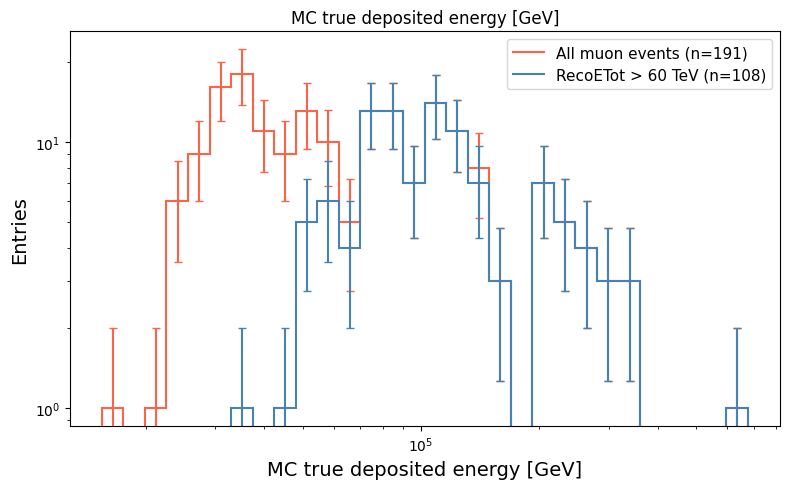

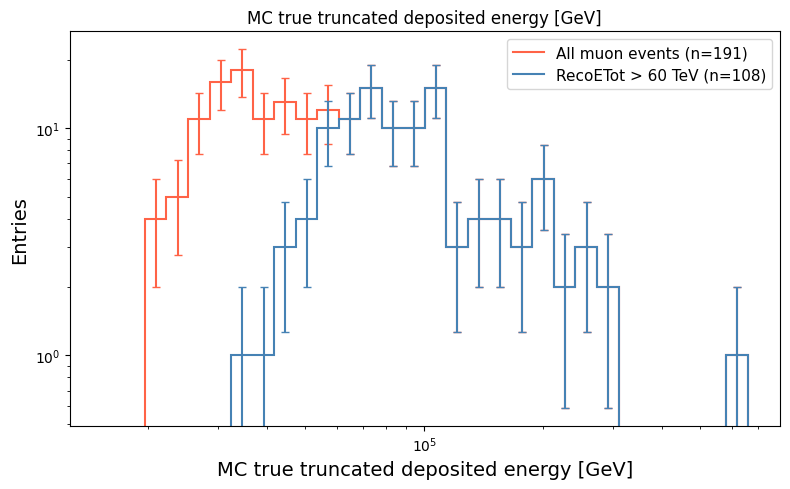

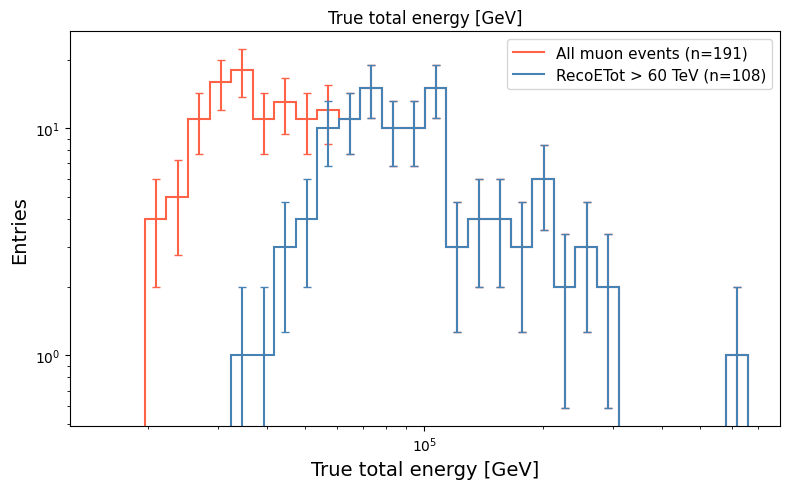

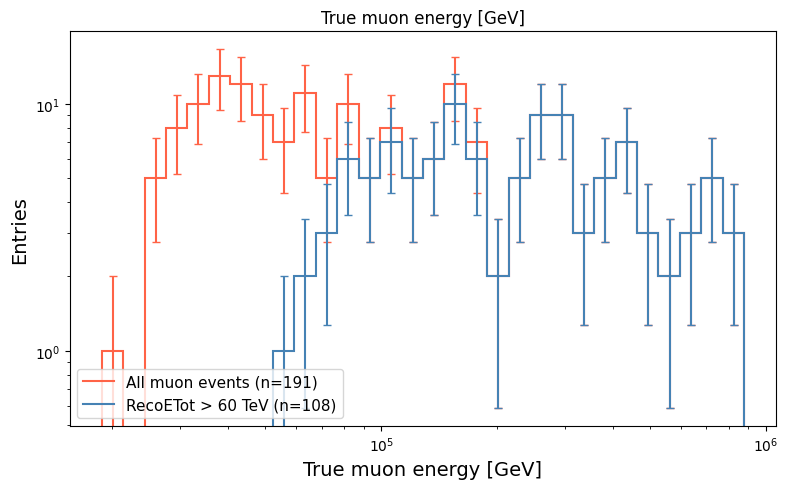

In [20]:
TRUE_ENERGY_VARS = [
    ('MCTrueDepositedEnergy',          'MC true deposited energy [GeV]'),
    ('MCTrueTruncatedDepositedEnergy', 'MC true truncated deposited energy [GeV]'),
    ('TrueETot',                       'True total energy [GeV]'),
    ('TrueMuonEnergy',                 'True muon energy [GeV]'),
    # ('TrueE1',                         'True cascade-1 energy [GeV]'),
    # ('TrueE2',                         'True cascade-2 energy [GeV]'),
    # ('PolyplopiaPrimaryEnergy',        'MuonGun primary (bundle) energy [GeV]'),
]

for var, xlabel in TRUE_ENERGY_VARS:
    plot_variable(var, xlabel=xlabel, title=xlabel, fname=f'true_{var}.pdf')


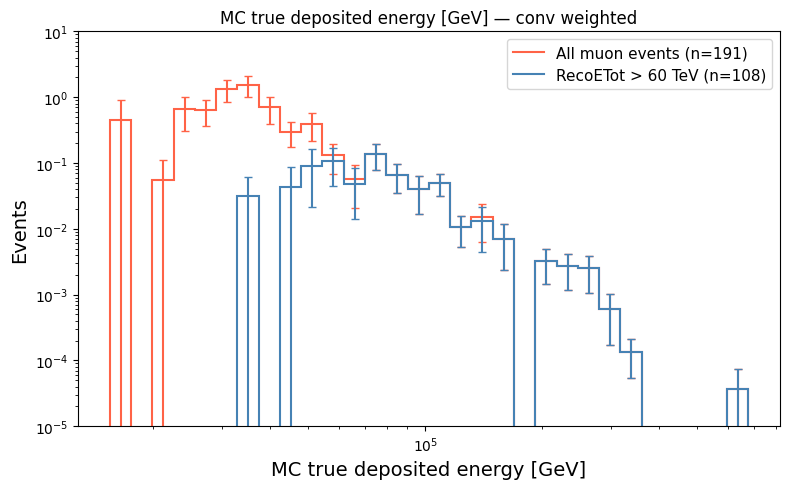

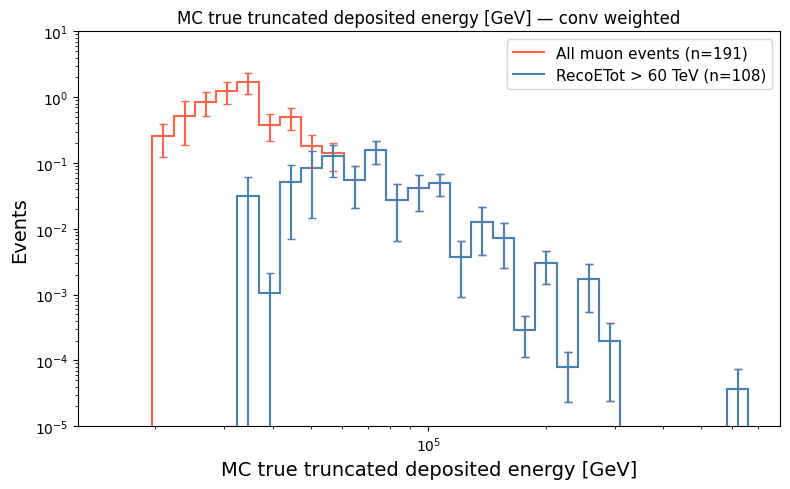

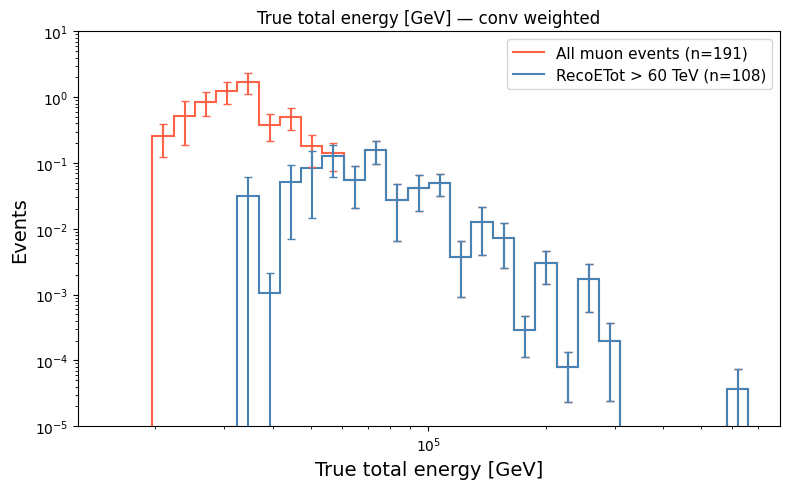

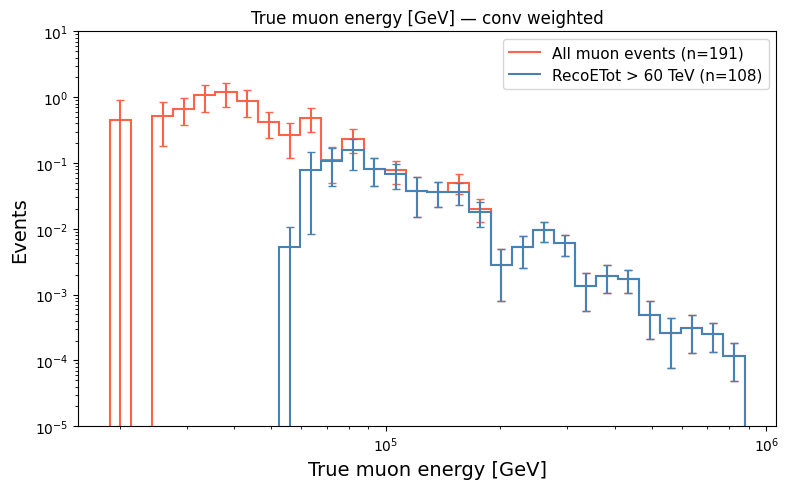

In [21]:
# Same true-energy distributions weighted by flux instead of raw MC counts.
# Weighted bin contents span ~4e-5 to ~2, so fix the y range rather than letting
# log autoscale follow the error bars down to ~1e-16.
YLIM_WEIGHTED = (1e-5, 1e1)

for var, xlabel in TRUE_ENERGY_VARS:
    plot_variable(var, xlabel=xlabel, weights=sim_weights_conv,
                  ylim=YLIM_WEIGHTED,
                  title=f'{xlabel} — conv weighted',
                  fname=f'true_{var}_convweighted.pdf')


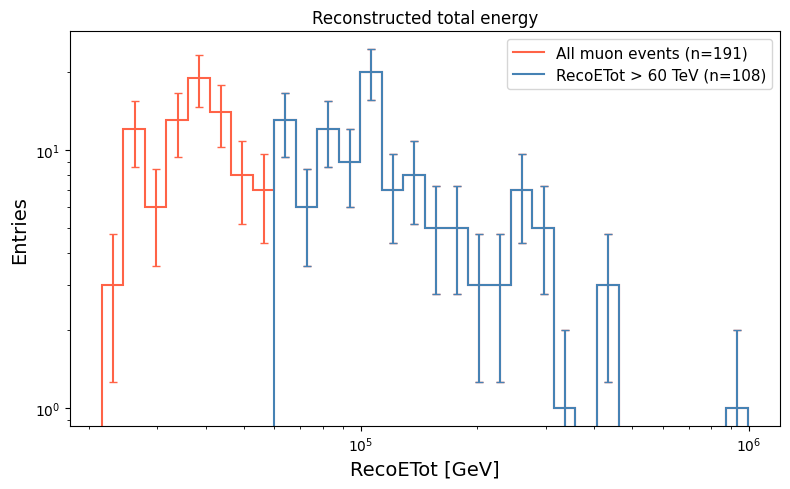

In [22]:
# Reference: the variable the 60 TeV cut is made on.
plot_variable('RecoETot', xlabel='RecoETot [GeV]',
              title='Reconstructed total energy', fname='RecoETot.pdf')


In [23]:
from matplotlib.colors import LogNorm

def plot_hist2d(xvar, yvar, low, high, nbins, xlabel=None, ylabel=None,
                weights=None, title=None, fname=None, cmap='viridis',
                diagonal=True):
    """2D histogram of yvar vs xvar on fixed log binning.

    low, high, nbins : the fixed binning, shared by both axes so the y=x
                       diagonal is meaningful.
    weights          : None for raw counts, or an array aligned with df_muon.
    """
    x = df_muon[xvar].values.astype(float)
    y = df_muon[yvar].values.astype(float)
    w = np.ones(len(x)) if weights is None else np.asarray(weights, dtype=float)

    m = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (x > 0) & (y > 0)

    bins = np.logspace(np.log10(low), np.log10(high), nbins + 1)
    h, xe, ye = np.histogram2d(x[m], y[m], bins=[bins, bins], weights=w[m])

    # fixed range: say how much falls outside it
    outside = m & ((x < low) | (x > high) | (y < low) | (y > high))
    if outside.any():
        print(f'{yvar} vs {xvar}: {outside.sum()} of {m.sum()} entries outside '
              f'[{low:.0e}, {high:.0e}]')

    fig, ax = plt.subplots(figsize=(7.5, 6))
    # histogram2d gives (nx, ny); pcolormesh wants (ny, nx)
    pc = ax.pcolormesh(xe, ye, np.ma.masked_where(h.T == 0, h.T),
                       norm=LogNorm(), cmap=cmap)
    cb = fig.colorbar(pc, ax=ax)
    cb.set_label('Events' if weights is not None else 'Entries', fontsize=13)

    if diagonal:
        ax.plot([low, high], [low, high], ls='--', c='white', lw=1.2, alpha=0.8)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_xlabel(xlabel or xvar, fontsize=14)
    ax.set_ylabel(ylabel or yvar, fontsize=14)
    ax.set_title(title or f'{yvar} vs {xvar}', fontsize=12)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / (fname or f'hist2d_{yvar}_vs_{xvar}.pdf'), bbox_inches='tight')
    plt.show()


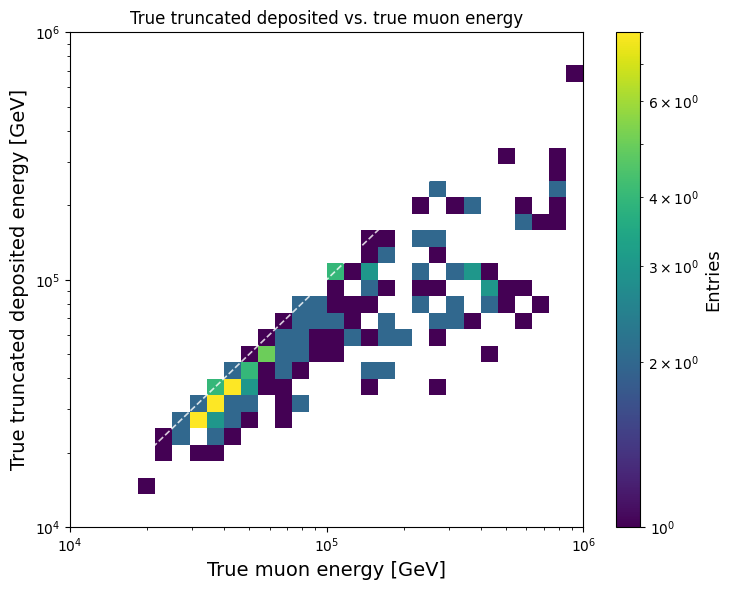

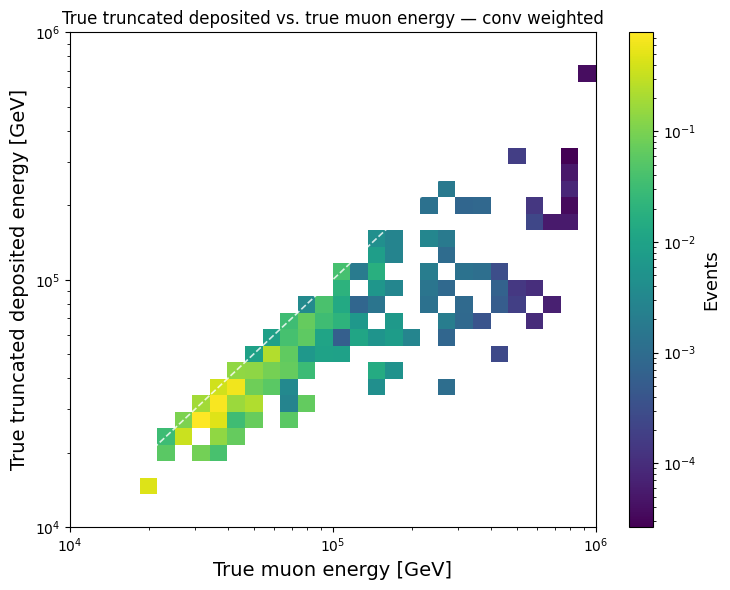

In [24]:
# Fixed binning for the 2D histograms
E2D_LOW   = 1e4
E2D_HIGH  = 1e6
E2D_NBINS = 30

XVAR, XLABEL = 'TrueMuonEnergy',                 'True muon energy [GeV]'
YVAR, YLABEL = 'MCTrueTruncatedDepositedEnergy', 'True truncated deposited energy [GeV]'

# Unweighted
plot_hist2d(XVAR, YVAR, E2D_LOW, E2D_HIGH, E2D_NBINS,
            xlabel=XLABEL, ylabel=YLABEL,
            title='True truncated deposited vs. true muon energy',
            fname='hist2d_truncdep_vs_truemuon.pdf')

# Conv weighted
plot_hist2d(XVAR, YVAR, E2D_LOW, E2D_HIGH, E2D_NBINS,
            xlabel=XLABEL, ylabel=YLABEL, weights=sim_weights_conv,
            title='True truncated deposited vs. true muon energy — conv weighted',
            fname='hist2d_truncdep_vs_truemuon_convweighted.pdf')
